# Notebook 02: The Divisibility Condition

**Goal:** Define divisibility precisely, implement the test, and show that
classical Markov chains always pass it.

By the end of this notebook you will be able to:
- State the divisibility condition as a matrix equation
- Use `check_divisibility()` to test a process (it needs the matrices it inverts to be non-singular,
  and returns `divisible: None`, undecided, when one is not)
- Explain intuitively why Markov chains are always divisible

<!-- sources:papers-1-3 -->
**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference; the full list is in `REFERENCES.md`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import StochasticProcess, make_markov_chain
from isp.divisibility import check_divisibility, indivisibility_signature
from isp.visualization import plot_transition_matrix

## 1. The Divisibility Condition

A process with transition matrices $\{T(t_i, t_j)\}$ is **divisible** if,
for every triple of times $t_1 < t_2 < t_3$, there is a valid stochastic matrix
$T(t_3, t_2)$ — all entries ≥ 0, columns summing to 1 — such that:

$$T(t_3, t_1) = T(t_3, t_2) \cdot T(t_2, t_1)$$

When $T(t_2, t_1)$ is invertible there is exactly one candidate, found by solving for it:

$$T(t_3, t_2) = T(t_3, t_1) \cdot T(t_2, t_1)^{-1}$$

and the process is divisible at that triple exactly when this matrix is a valid stochastic matrix.
When $T(t_2, t_1)$ is singular there is no inverse, and this shortcut cannot decide the question.

Asking this for *every* triple is stronger in form than Barandes's own condition (Paper 1, eq. 6),
which conditions on the initial time only: for each $t > t' > t_0$, is there a stochastic
$\tilde\Gamma(t \leftarrow t')$ with $\Gamma(t \leftarrow t_0) = \tilde\Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow t_0)$?
The two agree when the matrices are invertible.

In [2]:
# Build a simple divisible process: three explicit steps
T1 = np.array([[0.8, 0.3], [0.2, 0.7]])
T2 = np.array([[0.7, 0.4], [0.3, 0.6]])
T3 = np.array([[0.9, 0.2], [0.1, 0.8]])

proc = StochasticProcess(
    states=["0", "1"],
    transitions=[T1, T2, T3],
    times=[0.0, 1.0, 2.0, 3.0]
)

result = check_divisibility(proc)
print("Divisible?", result["divisible"])
print("Failure mode:", result["failure_mode"])

Divisible? True
Failure mode: None


In [3]:
# Manually verify: compute T(t3,t2) candidate and inspect
T_03 = proc.transition_from_to(0, 3)   # T(t=0 → t=3)
T_01 = proc.transition_from_to(0, 1)   # T(t=0 → t=1) = T1

T_13_candidate = T_03 @ np.linalg.inv(T_01)
print("T(t3,t2) candidate:")
print(T_13_candidate)
print("\nColumn sums:", T_13_candidate.sum(axis=0))
print("All entries >= 0:", np.all(T_13_candidate >= -1e-10))

T(t3,t2) candidate:
[[0.69 0.48]
 [0.31 0.52]]

Column sums: [1. 1.]
All entries >= 0: True


## 2. Why Markov Chains Are Always Divisible

For a time-homogeneous continuous-time Markov chain with a valid generator $L$
(off-diagonal entries ≥ 0, columns summing to 0), $T(t) = e^{Lt}$.
The composition law for matrix exponentials gives:
$$e^{L(t_3-t_1)} = e^{L(t_3-t_2)} \cdot e^{L(t_2-t_1)}$$

This identity holds for any times — Markov chains are divisible **by construction**.
The intermediate matrix is simply $T(t_3,t_2) = e^{L(t_3-t_2)}$, which is a valid
stochastic matrix for every valid generator $L$.

In [4]:
L = np.array([[-0.5,  0.3],
              [ 0.5, -0.3]])

times = [0.0, 0.5, 1.2, 2.0, 3.5]
markov = make_markov_chain(2, L, times)

result = check_divisibility(markov)
sig = indivisibility_signature(markov)

print(f"Divisible: {result['divisible']}")
print(f"Indivisibility signature: {sig:.2e}  (should be ~0)")

Divisible: True
Indivisibility signature: 0.00e+00  (should be ~0)


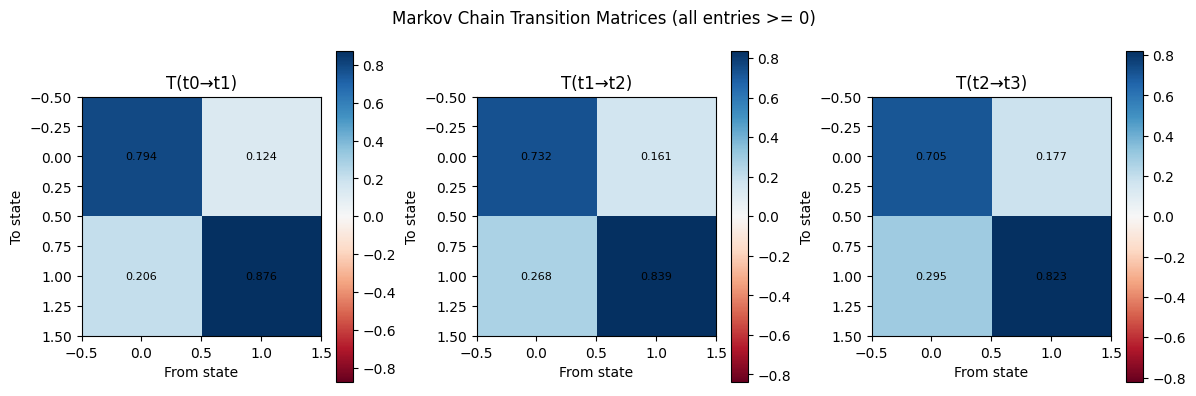

In [5]:
# Visualize the transition matrices
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, ax in enumerate(axes):
    plot_transition_matrix(markov.transitions[i],
                           title=f"T(t{i}\u2192t{i+1})", ax=ax)
plt.suptitle("Markov Chain Transition Matrices (all entries >= 0)")
plt.tight_layout()
plt.show()

## Summary

- Divisibility means the process can always be factored through any intermediate time
- The intermediate matrix must be non-negative with columns summing to 1
- Markov chains are always divisible — $T(t) = e^{Lt}$ guarantees it

**Next:** Notebook 03 constructs a process that *fails* this test —
and sees what quantum mechanics looks like from the stochastic side.